In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importación de la función BiAA matricial/tensorial mxnx1 con esquema Chen (Huber + Active Set)
from src.Robusted_Chen_biAA import robust_biarchetypal_analysis_huber

np.set_printoptions(precision=4, suppress=True)

In [3]:
# -------------------------------------------------------------------------
# 1. GENERACIÓN DE DATOS SINTÉTICOS Y OUTLIERS PARA BiAA
# -------------------------------------------------------------------------
rng = np.random.default_rng(42)

# Definimos dimensiones (N filas x M columnas)
N_samples, M_features = 100, 20
k_row_archetypes = 3     # Número de arquetipos por filas (k)
c_col_archetypes = 2     # Número de arquetipos por columnas (c)

# 1. Matriz de arquetipos latentes Z de dimensión (k, c)
true_Z = rng.uniform(low=0.1, high=0.9, size=(k_row_archetypes, c_col_archetypes))

# 2. Coeficientes Dirichlet para mezcla de filas (alpha: N x k) y columnas (gamma: c x M)
true_alpha = rng.dirichlet(np.ones(k_row_archetypes), size=N_samples)
true_gamma = rng.dirichlet(np.ones(c_col_archetypes), size=M_features).T

# 3. Matriz limpia reconstruida: X = alpha @ Z @ gamma
X_clean = true_alpha @ true_Z @ true_gamma

# 4. Inyección de contaminación (outliers extremos celda por celda)
X = X_clean.copy()
n_outliers = 15
row_idx = rng.integers(0, N_samples, size=n_outliers)
col_idx = rng.integers(0, M_features, size=n_outliers)

# Asignamos valores atípicos severos (ej. celda contaminada con valor 12.0 - 15.0)
for r, c_idx in zip(row_idx, col_idx):
    X[r, c_idx] += rng.uniform(12.0, 15.0)

print("--- INFORMACIÓN DE LOS DATOS ---")
print(f"Dimensiones de X: {X.shape}")
print(f"Arquetipos por filas (k): {k_row_archetypes} | Arquetipos por columnas (c): {c_col_archetypes}")
print(f"Celdas totales: {N_samples * M_features} | Celdas contaminadas manualmente: {n_outliers}")


--- INFORMACIÓN DE LOS DATOS ---
Dimensiones de X: (100, 20)
Arquetipos por filas (k): 3 | Arquetipos por columnas (c): 2
Celdas totales: 2000 | Celdas contaminadas manualmente: 15


In [5]:
# -------------------------------------------------------------------------
# 2. EJECUCIÓN DE ROBUST_BIARCHETYPAL_ANALYSIS_HUBER_MXNX1
# -------------------------------------------------------------------------
print("\nEjecutando Robust BiAA (Chen Huber + Active Set) mxnx1...")

alpha_rob, beta_rob, gamma_rob, theta_rob, Z_rob, weights_rob = robust_biarchetypal_analysis_huber(
    X, 
    k=k_row_archetypes, 
    c=c_col_archetypes,
    max_robust_iter=20, max_inner_iter=50, 
    epsilon=0.01,
    tol=1e-5, 
    seed=42, 
    verbose=False
)


Ejecutando Robust BiAA (Chen Huber + Active Set) mxnx1...


In [6]:
# -------------------------------------------------------------------------
# 3. VERIFICACIÓN DE ESTRUCTURA Y MÉTRICAS DE EVALUACIÓN
# -------------------------------------------------------------------------
X_hat_rob = alpha_rob @ Z_rob @ gamma_rob

def sse(X_true, X_reconstructed):
    return float(np.sum((X_true - X_reconstructed) ** 2))

def weighted_sse_rows(X_true, X_reconstructed, weights):
    return float(np.sum(weights[:, np.newaxis] * ((X_true - X_reconstructed) ** 2)))

sse_total = sse(X, X_hat_rob)
sse_ponderado = weighted_sse_rows(X, X_hat_rob, weights_rob)
filas_atipicas = np.sum(weights_rob < 0.2)

print("\n--- RESULTADOS Y VERIFICACIÓN DE DIMENSIONES ---")
print(f"Dim de Alpha (N x k): {alpha_rob.shape}")
print(f"Dim de Gamma (c x M): {gamma_rob.shape}")
print(f"Dim de Z (k x c):     {Z_rob.shape}")
print(f"Dim de weights_rob:   {weights_rob.shape}")

df_results = pd.DataFrame([{
    "Método": "Robusted_Chen_biAA_mxnx1 (Huber)",
    "Filas Atípicas (w < 0.2)": f"{filas_atipicas} / {N_samples}",
    "SSE Original (Total)": sse_total,
    "SSE Ponderado (Robusto)": sse_ponderado
}])

print(df_results.round(4))


--- RESULTADOS Y VERIFICACIÓN DE DIMENSIONES ---
Dim de Alpha (N x k): (100, 3)
Dim de Gamma (c x M): (2, 20)
Dim de Z (k x c):     (3, 2)
Dim de weights_rob:   (100,)
                             Método Filas Atípicas (w < 0.2)  \
0  Robusted_Chen_biAA_mxnx1 (Huber)                 80 / 100   

   SSE Original (Total)  SSE Ponderado (Robusto)  
0             2185.2471                   5.7514  


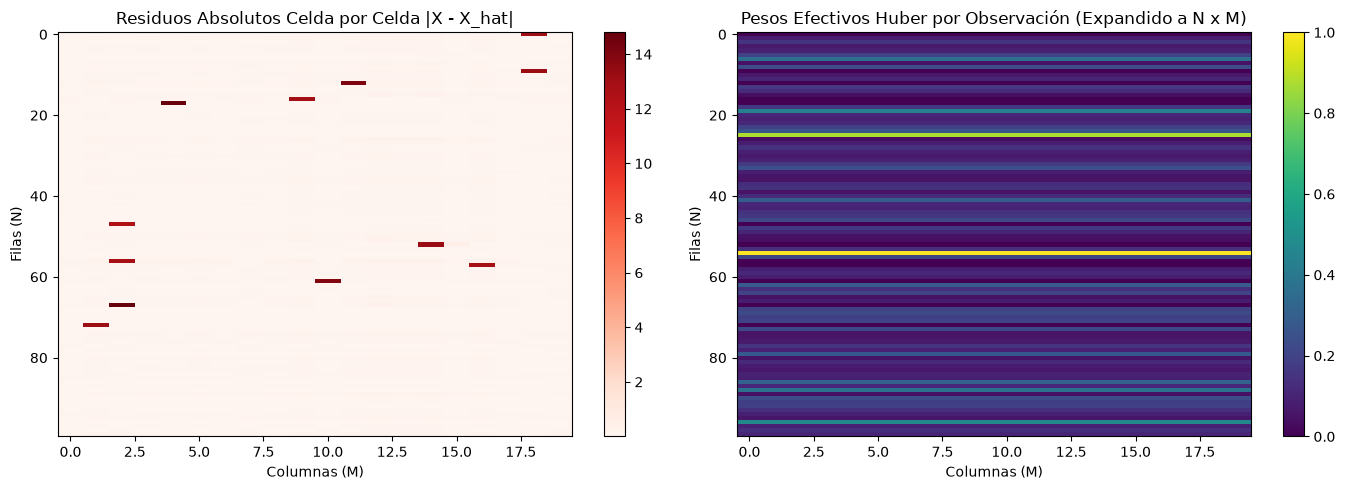

In [7]:
# -------------------------------------------------------------------------
# 4. VISUALIZACIÓN DE MATRIZ DE PESOS (DETECCIÓN DE OUTLIERS)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Calor de la matriz de residuos absolutos
residuos_abs = np.abs(X - X_hat_rob)
im0 = axes[0].imshow(residuos_abs, aspect='auto', cmap='Reds')
axes[0].set_title("Residuos Absolutos Celda por Celda |X - X_hat|")
axes[0].set_xlabel("Columnas (M)")
axes[0].set_ylabel("Filas (N)")
plt.colorbar(im0, ax=axes[0])

# Calor de los pesos Huber obtenidos por observación expandidos a (N, M)
W_mat_visual = np.repeat(weights_rob[:, np.newaxis], M_features, axis=1)
im1 = axes[1].imshow(W_mat_visual, aspect='auto', cmap='viridis', vmin=0, vmax=1)
axes[1].set_title("Pesos Efectivos Huber por Observación (Expandido a N x M)")
axes[1].set_xlabel("Columnas (M)")
axes[1].set_ylabel("Filas (N)")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()